# Python / Data Science Assignment

**Prepared for:** Tusher Nikam  
**Focus:** Python, Statistics, Machine Learning and Deep Learning


In [2]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
# Load dataset

#file_path = "UCI_Credit_Card.csv"
file_path =r"D:\Problem_Solving_Practice\Deep_Learning\Deep_Learning_Codes\DL_Projects\5.UCI_Credit_Card\UCI_Credit_Card.csv"
df = pd.read_csv(file_path)

print("Shape:", df.shape)
df.head()

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [4]:
# Basic dataset inspection

print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Target percentage:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


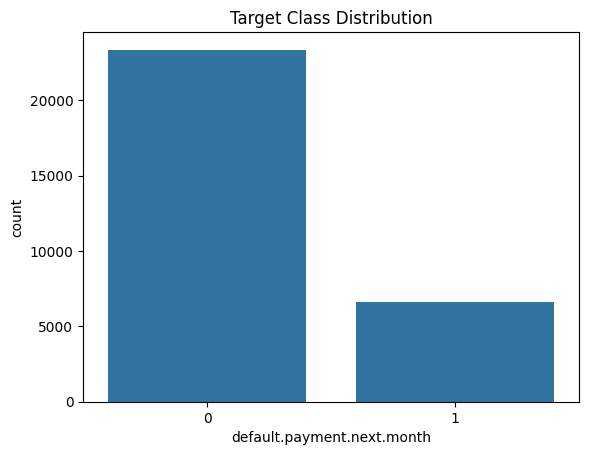

In [5]:
# Target distribution

target = "default.payment.next.month"

print(df[target].value_counts())
print("\nTarget percentage:")
print(df[target].value_counts(normalize=True) * 100)

sns.countplot(data=df, x=target)
plt.title("Target Class Distribution")
plt.show()

In [6]:
# Separate features and target

X = df.drop(columns=["ID", target])
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30000, 23)
y shape: (30000,)


In [7]:
# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (24000, 23)
Testing data : (6000, 23)


In [8]:
# Standardization

# Neural networks usually train better when numeric features
# are placed on comparable scales.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

Scaled training shape: (24000, 23)
Scaled testing shape : (6000, 23)


In [9]:
# Build ANN

model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

d:\Problem_Solving_Practice\Deep_Learning\.venv-1\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Dense(128, activation="relu")
# Dense(64, activation="relu")
# Dropout(0.30)

# optimizer="adam"
# epochs=100
# batch_size=64

In [11]:
# Compile the ANN

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [12]:
# Early stopping helps prevent unnecessary training

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8059 - loss: 0.4825 - val_accuracy: 0.8069 - val_loss: 0.4685
Epoch 2/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8141 - loss: 0.4496 - val_accuracy: 0.8119 - val_loss: 0.4583
Epoch 3/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8184 - loss: 0.4406 - val_accuracy: 0.8146 - val_loss: 0.4578
Epoch 4/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8201 - loss: 0.4367 - val_accuracy: 0.8125 - val_loss: 0.4492
Epoch 5/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8206 - loss: 0.4337 - val_accuracy: 0.8163 - val_loss: 0.4493
Epoch 6/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8216 - loss: 0.4324 - val_accuracy: 0.8148 - val_loss: 0.4490
Epoch 7/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8206 - loss: 0.4302 - val_accuracy: 0.8127 - val_loss: 0.4474
Epoch 8/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8212 - loss: 0.4304 - val_accuracy: 0.

In [13]:
# Early stopping helps prevent unnecessary training

# early_stop = EarlyStopping(
#     monitor="val_loss",
#     patience=5,
#     restore_best_weights=True
# )

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8235 - loss: 0.4259 - val_accuracy: 0.8146 - val_loss: 0.4504
Epoch 2/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8240 - loss: 0.4240 - val_accuracy: 0.8148 - val_loss: 0.4478
Epoch 3/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8244 - loss: 0.4235 - val_accuracy: 0.8123 - val_loss: 0.4453
Epoch 4/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8235 - loss: 0.4235 - val_accuracy: 0.8150 - val_loss: 0.4461
Epoch 5/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8229 - loss: 0.4228 - val_accuracy: 0.8125 - val_loss: 0.4451
Epoch 6/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8242 - loss: 0.4212 - val_accuracy: 0.8127 - val_loss: 0.4450
Epoch 7/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8259 - loss: 0.4208 - val_accuracy: 0.8133 - val_loss: 0.4463
Epoch 8/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8250 - loss: 0.4216 - val_accuracy: 0.

In [24]:
# Show training history

history_df = pd.DataFrame(history.history)
history_df.head(10)

,accuracy,loss,val_accuracy,val_loss
0,0.823490,0.425870,0.814583,0.450361
1,0.823958,0.424019,0.814792,0.447842
2,0.824375,0.423467,0.812292,0.445325
3,0.823542,0.423505,0.815000,0.446096
4,0.822865,0.422842,0.812500,0.445058
5,0.824219,0.421235,0.812708,0.444957
6,0.825938,0.420773,0.813333,0.446301
7,0.825000,0.421619,0.814792,0.444098
8,0.824948,0.421637,0.814375,0.445012
9,0.824948,0.419313,0.814583,0.445342


In [25]:
# Final training and validation values

print("Final Training Accuracy :", history.history["accuracy"][-1])
print("Final Training Loss     :", history.history["loss"][-1])
print("Final Validation Accuracy:", history.history["val_accuracy"][-1])
print("Final Validation Loss    :", history.history["val_loss"][-1])

Final Training Accuracy : 0.8305208086967468
Final Training Loss     : 0.4029282331466675
Final Validation Accuracy: 0.809583306312561
Final Validation Loss    : 0.45155635476112366


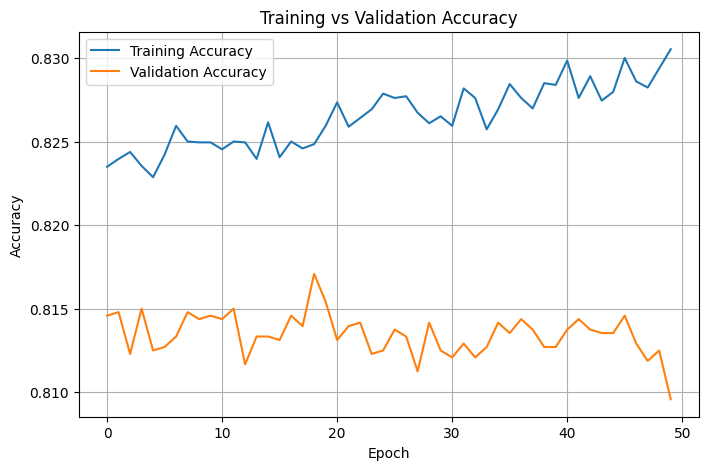

In [26]:
# Plot Accuracy

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

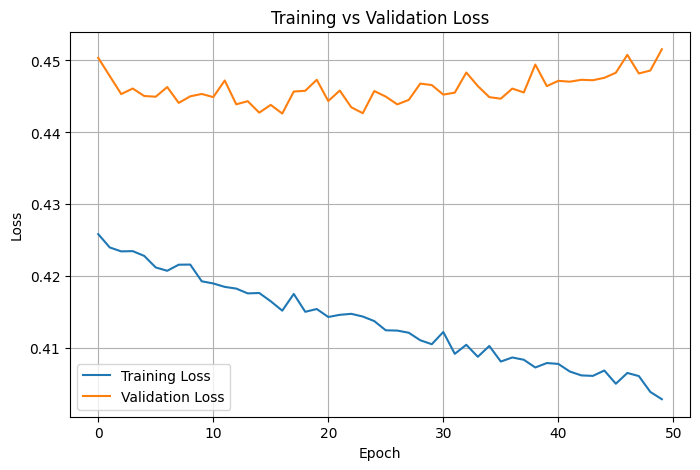

In [27]:
# Plot Loss

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
# Evaluate test data

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss     :", test_loss)
print("Test Accuracy :", test_accuracy)

Test Loss     : 0.44346651434898376
Test Accuracy : 0.8138333559036255


In [29]:
# Predictions

y_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print("First 10 probabilities:", y_prob[:10].ravel())
print("First 10 predictions  :", y_pred[:10])

First 10 probabilities: [0.05061225 0.09926955 0.12811746 0.11503093 0.04121136 0.0061416
 0.14019592 0.02055749 0.05993606 0.07412877]
First 10 predictions  : [0 0 0 0 0 0 0 0 0 0]


In [30]:
# Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.8138333333333333


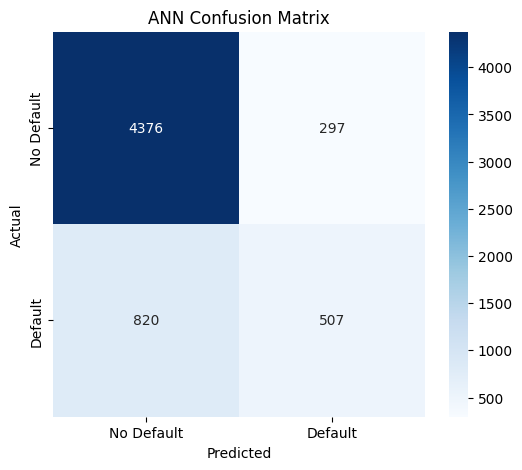

In [31]:
# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")
plt.show()

In [32]:
# Classification report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Default", "Default"]
    )
)

              precision    recall  f1-score   support

  No Default       0.84      0.94      0.89      4673
     Default       0.63      0.38      0.48      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.66      0.68      6000
weighted avg       0.80      0.81      0.80      6000



In [33]:
# Best validation epoch

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

Best validation-loss epoch: 17
Best validation loss: 0.44261789321899414
Best validation accuracy: 0.8170833587646484
